### Internally It Performs Recursive Text Splitter. The only difference is Separators. It uses different Separators for different document style

# Document Type : Python Code

In [32]:
from langchain_text_splitters import RecursiveCharacterTextSplitter,Language
from termcolor import colored, COLORS
from random import choice

In [33]:
python_code = """
import numpy as np
from typing import List, Optional

def calculate_mean(numbers: List[float]) -> float:
    '''Calculate the arithmetic mean of a list of numbers.
    
    Args:
        numbers: List of numerical values
        
    Returns:
        The mean value
    '''
    return sum(numbers) / len(numbers)

def calculate_median(numbers: List[float]) -> float:
    '''Calculate the median of a list of numbers.'''
    sorted_nums = sorted(numbers)
    n = len(sorted_nums)
    mid = n // 2
    
    if n % 2 == 0:
        return (sorted_nums[mid - 1] + sorted_nums[mid]) / 2
    return sorted_nums[mid]

class StatisticalAnalyzer:
    '''A class for performing statistical analysis on datasets.'''
    
    def __init__(self, data: List[float]):
        self.data = data
        self.mean = None
        self.median = None
    
    def analyze(self) -> dict:
        '''Perform complete statistical analysis.'''
        self.mean = calculate_mean(self.data)
        self.median = calculate_median(self.data)
        
        return {
            'mean': self.mean,
            'median': self.median,
            'count': len(self.data)
        }
    
    def get_summary(self) -> str:
        '''Return a formatted summary of the analysis.'''
        if self.mean is None:
            self.analyze()
        
        return f"Mean: {self.mean:.2f}, Median: {self.median:.2f}"

def main():
    '''Main execution function.'''
    data = [1.5, 2.3, 3.7, 4.2, 5.1]
    analyzer = StatisticalAnalyzer(data)
    results = analyzer.analyze()
    print(analyzer.get_summary())

if __name__ == "__main__":
    main()
"""

In [34]:
print(python_code)


import numpy as np
from typing import List, Optional

def calculate_mean(numbers: List[float]) -> float:
    '''Calculate the arithmetic mean of a list of numbers.

    Args:
        numbers: List of numerical values

    Returns:
        The mean value
    '''
    return sum(numbers) / len(numbers)

def calculate_median(numbers: List[float]) -> float:
    '''Calculate the median of a list of numbers.'''
    sorted_nums = sorted(numbers)
    n = len(sorted_nums)
    mid = n // 2

    if n % 2 == 0:
        return (sorted_nums[mid - 1] + sorted_nums[mid]) / 2
    return sorted_nums[mid]

class StatisticalAnalyzer:
    '''A class for performing statistical analysis on datasets.'''

    def __init__(self, data: List[float]):
        self.data = data
        self.mean = None
        self.median = None

    def analyze(self) -> dict:
        '''Perform complete statistical analysis.'''
        self.mean = calculate_mean(self.data)
        self.median = calculate_median(self.data)

        

In [35]:
python_splitter = RecursiveCharacterTextSplitter.from_language(
    language=Language.PYTHON,
    chunk_size = 700,
    chunk_overlap = 100
)

In [36]:
python_chunk = python_splitter.split_text(python_code)

In [37]:
type(python_chunk[0])

str

In [38]:
len(python_chunk)

4

In [39]:
def display_chunks(chunks):
    colors_list = list(COLORS.keys())[2:8]
    print(f"Total Number of Chunks: {len(chunks)}")
    for num, chunk in enumerate(chunks, 1):
        print(f"Chunk {num}: Length {len(chunk)} chars")
        print(colored(text=chunk, color=choice(colors_list)), end="\n\n")

In [40]:
display_chunks(python_chunk)

Total Number of Chunks: 4
Chunk 1: Length 592 chars
import numpy as np
from typing import List, Optional

def calculate_mean(numbers: List[float]) -> float:
    '''Calculate the arithmetic mean of a list of numbers.

    Args:
        numbers: List of numerical values

    Returns:
        The mean value
    '''
    return sum(numbers) / len(numbers)

def calculate_median(numbers: List[float]) -> float:
    '''Calculate the median of a list of numbers.'''
    sorted_nums = sorted(numbers)
    n = len(sorted_nums)
    mid = n // 2

    if n % 2 == 0:
        return (sorted_nums[mid - 1] + sorted_nums[mid]) / 2
    return sorted_nums[mid]

Chunk 2: Length 675 chars
class StatisticalAnalyzer:
    '''A class for performing statistical analysis on datasets.'''

    def __init__(self, data: List[float]):
        self.data = data
        self.mean = None
        self.median = None

    def analyze(self) -> dict:
        '''Perform complete statistical analysis.'''
        self.mean = calculat

In [41]:
python_splitter.get_separators_for_language(Language.PYTHON)

['\nclass ', '\ndef ', '\n\tdef ', '\n\n', '\n', ' ', '']

In [42]:
python_splitter.get_separators_for_language(Language.MARKDOWN)

['\n#{1,6} ',
 '```\n',
 '\n\\*\\*\\*+\n',
 '\n---+\n',
 '\n___+\n',
 '\n\n',
 '\n',
 ' ',
 '']

# JSON

In [44]:
from langchain_text_splitters import RecursiveJsonSplitter

In [45]:
JSON_DATA = {
    "company": "AI Research Corp",
    "departments": [
        {
            "name": "Machine Learning",
            "team_size": 25,
            "projects": [
                {
                    "id": "ML001",
                    "title": "Computer Vision System",
                    "description": "Developing advanced image recognition using CNNs",
                    "status": "active",
                    "team_members": ["Alice", "Bob", "Charlie"]
                },
                {
                    "id": "ML002",
                    "title": "NLP Platform",
                    "description": "Building transformer-based language models",
                    "status": "active",
                    "team_members": ["David", "Eve"]
                }
            ]
        },
        {
            "name": "Data Engineering",
            "team_size": 15,
            "projects": [
                {
                    "id": "DE001",
                    "title": "Data Pipeline",
                    "description": "ETL pipeline for real-time data processing",
                    "status": "active"
                }
            ]
        }
    ],
    "technologies": {
        "frameworks": ["TensorFlow", "PyTorch", "scikit-learn"],
        "languages": ["Python", "R", "Julia"],
        "cloud": ["AWS", "Google Cloud", "Azure"]
    },
    "metadata": {
        "founded": 2020,
        "headquarters": "San Francisco",
        "employees": 150
    }
}

In [46]:
json_splitter = RecursiveJsonSplitter(
    max_chunk_size=200
)

In [48]:
# returns a list of String

json_splitter.split_text(json_data=JSON_DATA)

['{"company": "AI Research Corp", "departments": [{"name": "Machine Learning", "team_size": 25, "projects": [{"id": "ML001", "title": "Computer Vision System", "description": "Developing advanced image recognition using CNNs", "status": "active", "team_members": ["Alice", "Bob", "Charlie"]}, {"id": "ML002", "title": "NLP Platform", "description": "Building transformer-based language models", "status": "active", "team_members": ["David", "Eve"]}]}, {"name": "Data Engineering", "team_size": 15, "projects": [{"id": "DE001", "title": "Data Pipeline", "description": "ETL pipeline for real-time data processing", "status": "active"}]}]}',
 '{"technologies": {"frameworks": ["TensorFlow", "PyTorch", "scikit-learn"], "languages": ["Python", "R", "Julia"], "cloud": ["AWS", "Google Cloud", "Azure"]}}',
 '{"metadata": {"founded": 2020, "headquarters": "San Francisco", "employees": 150}}']

In [50]:
# returns a list of Json Objects 

json_chunks = json_splitter.split_json(json_data=JSON_DATA)

In [51]:
display_chunks(json_chunks)

Total Number of Chunks: 3
Chunk 1: Length 2 chars
{'company': 'AI Research Corp', 'departments': [{'name': 'Machine Learning', 'team_size': 25, 'projects': [{'id': 'ML001', 'title': 'Computer Vision System', 'description': 'Developing advanced image recognition using CNNs', 'status': 'active', 'team_members': ['Alice', 'Bob', 'Charlie']}, {'id': 'ML002', 'title': 'NLP Platform', 'description': 'Building transformer-based language models', 'status': 'active', 'team_members': ['David', 'Eve']}]}, {'name': 'Data Engineering', 'team_size': 15, 'projects': [{'id': 'DE001', 'title': 'Data Pipeline', 'description': 'ETL pipeline for real-time data processing', 'status': 'active'}]}]}

Chunk 2: Length 1 chars
{'technologies': {'frameworks': ['TensorFlow', 'PyTorch', 'scikit-learn'], 'languages': ['Python', 'R', 'Julia'], 'cloud': ['AWS', 'Google Cloud', 'Azure']}}

Chunk 3: Length 1 chars
{'metadata': {'founded': 2020, 'headquarters': 'San Francisco', 'employees': 150}}



# Markdown

In [53]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

In [54]:
MARKDOWN_TEXT = """# Artificial Intelligence Overview

Artificial intelligence is transforming technology and shaping the future of computing.

## Machine Learning

Machine learning is a subset of AI that focuses on pattern recognition.

### Supervised Learning

Supervised learning algorithms learn from labeled training data.
They make predictions based on input-output pairs.

Common algorithms include:
- Linear regression
- Decision trees
- Support vector machines

### Unsupervised Learning

Unsupervised learning finds patterns in unlabeled data.
It's useful for clustering and dimensionality reduction.

Common techniques:
- K-means clustering
- Principal component analysis
- Hierarchical clustering

## Deep Learning

Deep learning uses neural networks with multiple layers.

### Neural Networks

Neural networks are inspired by biological neurons.
They consist of interconnected nodes organized in layers.

### Convolutional Neural Networks

CNNs excel at image recognition tasks.
They use convolutional layers to detect features hierarchically.

## Applications

AI has applications across multiple domains:

### Healthcare

- Disease diagnosis
- Drug discovery
- Medical imaging analysis

### Finance

- Fraud detection
- Algorithmic trading
- Risk assessment
"""

In [55]:
# Explicitly we have to mention the separatorss

headers_to_split_on = [
    ("#", "Header_1"),
    ("##", "Header_2"),
    ("###", "Header_3")
]

In [60]:
markdown_splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=headers_to_split_on,
    strip_headers=False
)

In [63]:
markdown_chunks = markdown_splitter.split_text(MARKDOWN_TEXT)

In [64]:
for doc in markdown_chunks:
    print(doc.page_content, end="\n\n")

# Artificial Intelligence Overview  
Artificial intelligence is transforming technology and shaping the future of computing.

## Machine Learning  
Machine learning is a subset of AI that focuses on pattern recognition.

### Supervised Learning  
Supervised learning algorithms learn from labeled training data.
They make predictions based on input-output pairs.  
Common algorithms include:
- Linear regression
- Decision trees
- Support vector machines

### Unsupervised Learning  
Unsupervised learning finds patterns in unlabeled data.
It's useful for clustering and dimensionality reduction.  
Common techniques:
- K-means clustering
- Principal component analysis
- Hierarchical clustering

## Deep Learning  
Deep learning uses neural networks with multiple layers.

### Neural Networks  
Neural networks are inspired by biological neurons.
They consist of interconnected nodes organized in layers.

### Convolutional Neural Networks  
CNNs excel at image recognition tasks.
They use convoluti

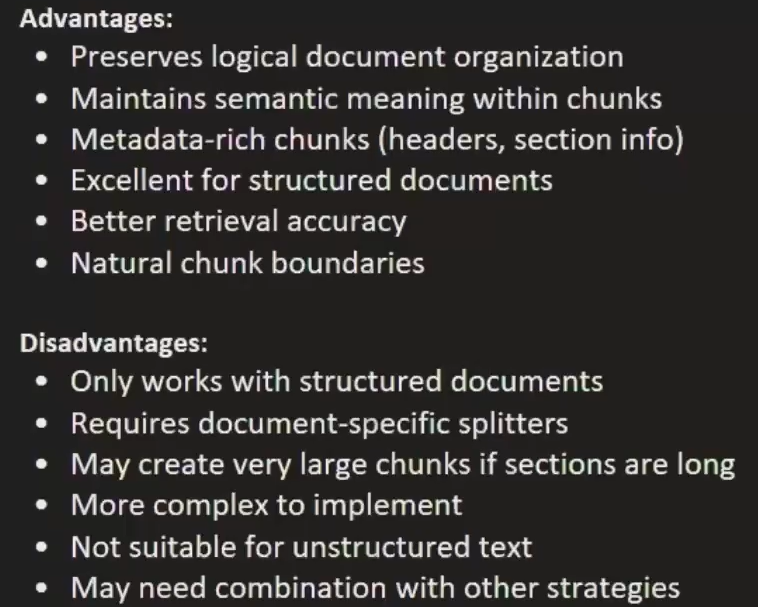